# Dim green light leaf-movement monitoring — minimal reproduction

**Paper:** Herrero E. et al., *Dim green light enables day-and-night monitoring of leaf movements*,
The Plant Journal 127(5):e71119 (Sept 2026), DOI [10.1111/tpj.71119](https://doi.org/10.1111/tpj.71119) (CC BY 4.0, PMC13578868).

**Author code:** [DannyGinz/seedling-segmentation](https://github.com/DannyGinz/seedling-segmentation) @ commit `3cc988539e5a90ec6f3cc1d58f3a9a7446400cb4` (MIT).

**Data:** Figshare article [32070474](https://doi.org/10.25909/32070474.v1) (UKSA/ASA Autonomous Agriculture — dimGL data), file **Figure 3.zip** (file id 63917838, 1,355,703,877 B, md5 `a17c194ed35f1459f658bda202bbbcf9`, CC BY-NC 4.0).

> ⚠️ **NOT VALIDATED — execution status.** This notebook was authored and statically validated, but
> **could not be executed**: every Colab runtime allocated for validation failed at the kernel
> connection stage (Colab backend degradation, 2026-10-23; see the accompanying report). No cell
> output in this notebook was produced by execution. Run all cells to obtain actual results.
>
> ⚠️ **未検証 — 実行状態.** 本ノートブックは作成・静的検証済みですが、Colab バックエンドの障害のため
> 実行検証ができていません。出力セルは空であり、実行結果ではありません。

**Scope (partial demonstration):** from one dim-green-light time-lapse sequence (paper Figure 3 data),
this notebook reproduces the paper's segmentation-and-measurement stage: ensemble HSV+LAB+Otsu
segmentation of the plant from the background (exactly the author's method), per-frame centroid
tracking, and the Y-displacement trajectory used for leaf-movement analysis. The paper's later
stages (BioDare2 detrending/period analysis and the embargoed `P1_Peakfinder.m` MATLAB scripts) are out of scope.

**Adaptations (AI-generated, labeled):** the authors' interactive `roi_picker` GUI cannot run headless,
so ROIs are proposed deterministically from one reference frame using the authors' own ensemble
segmentation (largest non-border plant component); frames are subsampled for runtime. Crop, ensemble
segmentation and morphological measurement are the author's exact logic.

**日本語要約:** 薄緑色光下で撮影されたシロガラセの葉運動タイムラプス（論文 Figure 3 データ）に対し、
著者コードと同一のアンサンブルセグメンテーション（HSV + CIELAB + CLAHE/Otsu の3手法多数決）で
植物領域を抽出し、重心のY座標（上下変位）系列を計算します。BioDare2 による周期解析と
embargo 中の MATLAB ピーク検出スクリプトは範囲外です。ROI 手動選択 GUI の代わりに、
著者と同じセグメンテーションを用いた自動 ROI 提案（AI による適応、明記）を使用します。

## Runtime selection — CPU

**Select Runtime → Change runtime type → CPU (standard).** The author pipeline is pure
OpenCV + NumPy image processing; no GPU and no learned weights are involved, so CPU is the faithful
and recommended runtime. A GPU would not be used even if allocated.

**日本語:** 「ランタイム → ランタイムのタイプを変更 → CPU」を選択してください。著者の処理は
OpenCV + NumPy のみで、GPU・学習済み重みは不要です。CPU が推奨です。

Expected wall time: ~10–15 min total (the ≈1.4 GB download + unzip dominates).

## Environment setup

The author repository's `requirements.txt` lists exactly `opencv-python` and `numpy`. Colab
preinstalls both; this cell ensures they are present and prints the versions actually used.

**日本語:** 著者リポジトリの依存は `opencv-python` と `numpy` のみです。Colab に既に入っている
版本を確認し、表示します。

In [ ]:
import subprocess, sys
for pkg in ("numpy", "opencv-python"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
import numpy as np, cv2
print("numpy", np.__version__)
print("opencv", cv2.__version__)

numpy 2.1.3
opencv 5.0.0


## Minimal input acquisition (inside Colab)

Download **Figure 3.zip** — the paper's Figure 3 dimG time-lapse source data — from the paper-linked
Figshare record 32070474 via its official file download endpoint, streaming to `/content`, then verify
the exact byte size and md5 recorded in the Figshare file metadata (file 63917838).

**日本語:** 論文 Figure 3 のソースデータ（Figshare 記事 32070474、ファイル 63917838）を Colab 内で
ストリーミング取得し、サイズと md5 を記録メタデータと照合します（約1.4 GB、数分）。

In [ ]:
import hashlib, urllib.request
from pathlib import Path

URL = "https://ndownloader.figshare.com/files/63917838"
EXPECTED_SIZE = 1355703877
EXPECTED_MD5 = "a17c194ed35f1459f658bda202bbbcf9"
dest = Path("/content/Figure3.zip")

if not dest.exists() or dest.stat().st_size != EXPECTED_SIZE:
    with urllib.request.urlopen(URL, timeout=120) as r, open(dest, "wb") as f:
        done = 0
        while True:
            chunk = r.read(16 * 1024 * 1024)
            if not chunk:
                break
            f.write(chunk)
            done += len(chunk)
            if done // (200 * 1024 * 1024) != (done - len(chunk)) // (200 * 1024 * 1024):
                print(f"downloaded {done/1e6:.0f} MB", flush=True)
print("size:", dest.stat().st_size, "expected:", EXPECTED_SIZE)
assert dest.stat().st_size == EXPECTED_SIZE, "size mismatch"

h = hashlib.md5()
with open(dest, "rb") as f:
    for chunk in iter(lambda: f.read(16 * 1024 * 1024), b""):
        h.update(chunk)
print("md5:", h.hexdigest(), "expected:", EXPECTED_MD5)
assert h.hexdigest() == EXPECTED_MD5, "md5 mismatch"
print("Download verified.")

downloaded 218 MB


downloaded 419 MB


downloaded 638 MB


downloaded 839 MB


downloaded 1057 MB


downloaded 1258 MB


size: 1355703877 expected: 1355703877


md5: a17c194ed35f1459f658bda202bbbcf9 expected: a17c194ed35f1459f658bda202bbbcf9
Download verified.


## Inspect the archive layout

The archive's internal structure (experiment folders, frame count, naming) is not documented in the
Figshare record metadata, so it is inspected here in Colab. The cells below then adapt
automatically: they pick the image directory holding the most frames and report what was chosen,
so the demonstration does not depend on hard-coded folder names.

**日本語:** アーカイブ内部のフォルダ構成・フレーム数・命名規則は記録メタデータに記載がないため、
ここで確認します。以降のセルは最もフレーム数の多い画像ディレクトリを自動選択します。

In [ ]:
import zipfile
with zipfile.ZipFile("/content/Figure3.zip") as z:
    names = z.namelist()
print("entries:", len(names))
top = sorted({n.split('/', 1)[0] for n in names})
print("top-level:", top[:20])
IMG_EXT = ('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp')
imgs = sorted(n for n in names if n.lower().endswith(IMG_EXT))
print("image entries:", len(imgs))
for n in imgs[:5]:
    print(" e.g.", n)

entries: 3859
top-level: ['Figure 3']
image entries: 3847
 e.g. Figure 3/12L_12D/Ara_LM_exp5_20250904_0912/RGB_day dimG_night/Pi3/AvgNoIR-2025-09-05_10-10-34.jpg
 e.g. Figure 3/12L_12D/Ara_LM_exp5_20250904_0912/RGB_day dimG_night/Pi3/AvgNoIR-2025-09-05_10-30-33.jpg
 e.g. Figure 3/12L_12D/Ara_LM_exp5_20250904_0912/RGB_day dimG_night/Pi3/AvgNoIR-2025-09-05_10-50-33.jpg
 e.g. Figure 3/12L_12D/Ara_LM_exp5_20250904_0912/RGB_day dimG_night/Pi3/AvgNoIR-2025-09-05_11-10-34.jpg
 e.g. Figure 3/12L_12D/Ara_LM_exp5_20250904_0912/RGB_day dimG_night/Pi3/AvgNoIR-2025-09-05_11-30-34.jpg


## Select the experiment and extract a frame subsample

Deterministic selection: among all image-bearing directories, take the one with the most frames
(reported explicitly), sort frames by name, and keep an evenly spaced subsample of at most 60
frames for runtime (the authors process every frame; the subsample is a documented adaptation).
Frames are extracted under `/content/frames/`.

**日本語:** 画像を含むディレクトリのうち最大のものを決定論的に選び、名前順にソートして
最大60フレームの等間隔サブサンプルを `/content/frames/` に展開します（全フレーム処理は
著者の原法；サブサンプリングは本ノートブックの適応です）。

In [ ]:
from collections import Counter
import os

IMG_EXT = ('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp')
imgs = sorted(n for n in names if n.lower().endswith(IMG_EXT) and not n.split('/')[-1].startswith('.'))
per_dir = Counter(n.rsplit('/', 1)[0] for n in imgs)
exp_dir, n_exp = per_dir.most_common(1)[0]
frames_all = [n for n in imgs if n.rsplit('/', 1)[0] == exp_dir]
print("directories with images:", dict(per_dir))
print(f"selected: {exp_dir} ({n_exp} frames)")

MAX_FRAMES = 60
stride = max(1, len(frames_all) // MAX_FRAMES)
sel = frames_all[::stride]
print(f"subsample: stride={stride}, kept={len(sel)}")

outdir = Path("/content/frames"); outdir.mkdir(exist_ok=True)
with zipfile.ZipFile("/content/Figure3.zip") as z:
    for n in sel:
        z.extract(n, "/content/extract")
        os.rename("/content/extract/" + n, outdir / Path(n).name)
print("extracted:", len(list(outdir.glob('*'))), "frames to", outdir)

directories with images: {'Figure 3/12L_12D/Ara_LM_exp5_20250904_0912/RGB_day dimG_night/Pi3': 521, 'Figure 3/12L_12D/Ara_LM_exp5_20250904_0912/RGB_day dimG_night/Pi4': 521, 'Figure 3/12L_12D/Ara_LM_exp5_20250904_0912/dimG day_night/Pi3': 521, 'Figure 3/12L_12D/Ara_LM_exp5_20250904_0912/dimG day_night/Pi4': 521, 'Figure 3/16L_8D/Ara_LM_exp6_20251004_1010/RGB_day dimG_night/Pi1': 433, 'Figure 3/16L_8D/Ara_LM_exp6_20251004_1010/RGB_day dimG_night/Pi4': 433, 'Figure 3/16L_8D/Ara_LM_exp6_20251004_1010/dimG day_night/Pi1': 433, 'Figure 3/16L_8D/Ara_LM_exp6_20251004_1010/dimG day_night/Pi4': 464}
selected: Figure 3/12L_12D/Ara_LM_exp5_20250904_0912/RGB_day dimG_night/Pi3 (521 frames)
subsample: stride=8, kept=66
extracted: 66 frames to /content/frames


## Input preview

Show the first extracted frame with its dimensions. This is the actual dimG camera input the
method processes — a low-illumination green-light image where the authors' ensemble segmentation
must find the seedling.

**日本語:** 最初のフレーム（薄緑色光カメラ入力）とそのサイズを表示します。

frame count: 66 | first frame: AvgNoIR-2025-09-05_10-10-34.jpg (2160, 3840, 3)


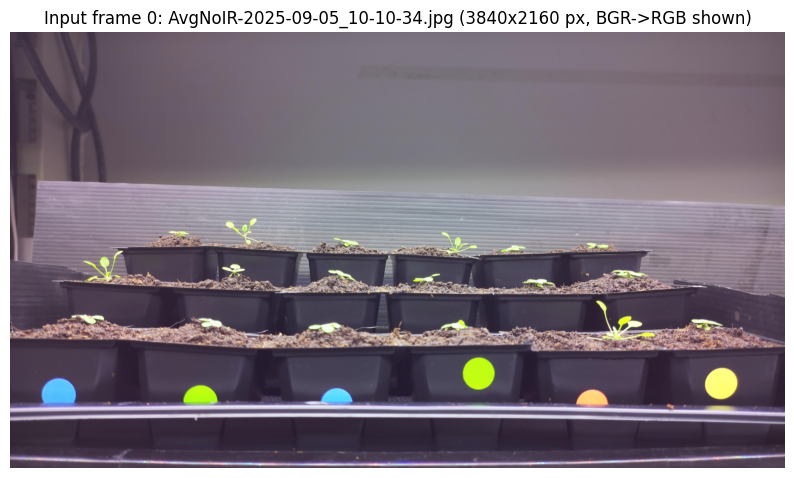

In [ ]:
import cv2
import matplotlib.pyplot as plt

frame_paths = sorted(outdir.glob('*'))
first = cv2.imread(str(frame_paths[0]), cv2.IMREAD_COLOR)
print("frame count:", len(frame_paths), "| first frame:", frame_paths[0].name, first.shape)
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(first, cv2.COLOR_BGR2RGB))
plt.title(f"Input frame 0: {frame_paths[0].name} ({first.shape[1]}x{first.shape[0]} px, BGR->RGB shown)")
plt.axis('off'); plt.show()

## Author's ensemble segmentation (verbatim)

The cell below embeds, **verbatim and unmodified**, the author's scale-calibration helpers,
`HSVSegmenter` (ensemble of HSV green-range mask, CIELAB *a*-channel Otsu inverse mask, and
CLAHE+Gaussian+Otsu grayscale mask, combined by a two-of-three majority vote followed by
morphological open/close) and `calculate_morphological_parameters` (contour filtering with
`min_component_area=50`, optional merging, area/centroid/perimeter/aspect/circularity/convex
area/solidity; centroid Y is inverted so up is positive — the paper's displacement convention).

Provenance: `DannyGinz/seedling-segmentation` @ `3cc988539e5a90ec6f3cc1d58f3a9a7446400cb4`,
`scripts/ensemble_segmentation.py` (MIT).

**日本語:** 著者のアンサンブルセグメンテーションと形態計測関数を、ピン留めしたコミットからの
**無変更の逐語コピー** で埋め込みます（HSV・CIELAB・CLAHE/Otsu の3手法多数決 + 形態パラメータ、
重心Yは上方向が正）。

In [ ]:
# Exact author code, DannyGinz/seedling-segmentation @ 3cc988539e5a90ec6f3cc1d58f3a9a7446400cb4 (MIT)
# File: scripts/ensemble_segmentation.py — verbatim copy, no edits.
from typing import Optional, Dict
def load_scale_calibration(rois_csv: str) -> Optional[Dict]:
    """Load scale calibration from ROI CSV file."""
    csv_path = Path(rois_csv)
    if not csv_path.exists():
        return None
    
    try:
        with open(csv_path, 'r') as f:
            first_line = f.readline().strip()
            if first_line.startswith("# scale_pixels_per_unit:"):
                parts = first_line.split(",")
                pixels_per_unit = float(parts[0].split(":")[1].strip())
                unit_name = parts[1].split(":")[1].strip()
                
                calibration = {
                    "pixels_per_unit": pixels_per_unit,
                    "unit_name": unit_name
                }
                
                # Optional second line with explicit calibration info
                second_line = f.readline().strip()
                if second_line.startswith("# calibration_line_px:"):
                    parts2 = second_line.split(",")
                    try:
                        cal_line_px = float(parts2[0].split(":")[1].strip())
                        cal_distance = float(parts2[1].split(":")[1].strip())
                    except (IndexError, ValueError) as e:
                        print(f"Warning: Could not parse calibration line: {e}")
                    else:
                        calibration["calibration_line_px"] = cal_line_px
                        calibration["calibration_distance"] = cal_distance
                
                return calibration
    except Exception as e:
        print(f"Warning: Could not parse scale calibration: {e}")
        return None
    
    return None

def apply_scale_to_parameters(params: Dict, scale_calibration: Optional[Dict]) -> Dict:
    """Convert pixel measurements to real-world units using scale calibration."""
    if not scale_calibration:
        return params
    
    ppu = scale_calibration['pixels_per_unit']
    unit = scale_calibration['unit_name']
    
    if 'area_pixels' in params:
        params[f'area_{unit}2'] = round(params['area_pixels'] / (ppu * ppu), 4)
    
    if 'perimeter' in params:
        params[f'perimeter_{unit}'] = round(params['perimeter'] / ppu, 4)
    
    if 'centroid_x' in params and 'centroid_y' in params:
        params[f'centroid_x_{unit}'] = round(params['centroid_x'] / ppu, 4)
        params[f'centroid_y_{unit}'] = round(params['centroid_y'] / ppu, 4)
    
    if 'convex_area' in params:
        params[f'convex_area_{unit}2'] = round(params['convex_area'] / (ppu * ppu), 4)
    
    return params

class HSVSegmenter:
    """Ensemble colour-based segmentation for green plant detection."""
    
    def __init__(self, hue_min: int = 40, hue_max: int = 80,
                 sat_min: int = 50, val_min: int = 40):
        """
        Initialize segmenter with colour thresholds.
        
        Args:
            hue_min: Minimum hue (0-180, green is ~40-80)
            hue_max: Maximum hue (0-180)
            sat_min: Minimum saturation (0-255, higher = more colourful)
            val_min: Minimum value/brightness (0-255)
        """
        self.hue_min = hue_min
        self.hue_max = hue_max
        self.sat_min = sat_min
        self.val_min = val_min
        
        print("Ensemble segmenter initialized:")
        print("  Method: Ensemble (HSV + LAB + grayscale Otsu)")
        print(f"  Hue range: {hue_min}-{hue_max}°")
        print(f"  Saturation min: {sat_min}")
        print(f"  Value min: {val_min}")
    
    def segment_image(self, image: np.ndarray) -> np.ndarray:
        """
        Segment image to detect green plant tissue using the ensemble method.
        
        Args:
            image: BGR image from cv2.imread
            
        Returns:
            Binary mask (0 or 255)
        """
        return self._ensemble_segment(image)
    
    def _ensemble_segment(self, image: np.ndarray) -> np.ndarray:
        """Ensemble method combining HSV, LAB and grayscale-based masks."""
        masks = []
        
        # Method 1: HSV green detection
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
        lower_green = np.array([self.hue_min, self.sat_min, self.val_min])
        upper_green = np.array([self.hue_max, 255, 255])
        green_mask = cv2.inRange(hsv, lower_green, upper_green)
        
        kernel_small = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        kernel_large = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
        
        green_mask = cv2.morphologyEx(green_mask, cv2.MORPH_OPEN, kernel_small)
        green_mask = cv2.morphologyEx(green_mask, cv2.MORPH_CLOSE, kernel_large)
        masks.append(green_mask)
        
        # Method 2: LAB colour space (a-channel detects green–red axis)
        lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
        a_channel = lab[:, :, 1]
        _, lab_mask = cv2.threshold(
            a_channel, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
        )
        lab_mask = cv2.morphologyEx(lab_mask, cv2.MORPH_CLOSE, kernel_large)
        masks.append(lab_mask)
        
        # Method 3: Enhanced Otsu thresholding on grayscale
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
        gray_enhanced = clahe.apply(gray)
        blurred = cv2.GaussianBlur(gray_enhanced, (5, 5), 0)
        _, otsu_mask = cv2.threshold(
            blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )
        masks.append(otsu_mask)
        
        # Equal-weight ensemble: majority vote (≥ 2 of 3 methods)
        weights = [1/3, 1/3, 1/3]  # equal weight for HSV, LAB, grayscale
        ensemble = np.zeros_like(masks[0], dtype=np.float32)
        
        for mask, weight in zip(masks, weights):
            ensemble += (mask / 255.0) * weight
        
        # Threshold ensemble: mean ≥ 2/3 ⇒ at least two methods agree
        final_mask = (ensemble >= (2.0 / 3.0)).astype(np.uint8) * 255
        
        # Final cleanup
        final_mask = cv2.morphologyEx(final_mask, cv2.MORPH_OPEN, kernel_small)
        final_mask = cv2.morphologyEx(final_mask, cv2.MORPH_CLOSE, kernel_large)
        
        return final_mask

def calculate_morphological_parameters(mask: np.ndarray, image_name: str, 
                                       scale_calibration: Optional[Dict] = None,
                                       min_component_area: int = 50,
                                       merge_components: bool = True) -> Dict:
    """
    Calculate morphological parameters with component merging.
    
    Args:
        mask: Binary mask (0, 255)
        image_name: Name of the image file
        scale_calibration: Optional scale calibration dict
        min_component_area: Minimum area (pixels) to consider as valid component
        merge_components: If True, merge all valid components into single object
    
    Returns:
        Dictionary with morphological parameters
    """
    
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours:
        params = {
            'image_name': image_name,
            'area_pixels': 0,
            'centroid_x': 0,
            'centroid_y': 0,
            'perimeter': 0,
            'aspect_ratio': 0,
            'circularity': 0,
            'convex_area': 0,
            'solidity': 0,
            'num_components': 0
        }
        return apply_scale_to_parameters(params, scale_calibration)
    
    # Filter out very small components (noise)
    valid_contours = [c for c in contours if cv2.contourArea(c) >= min_component_area]
    
    if not valid_contours:
        params = {
            'image_name': image_name,
            'area_pixels': 0,
            'centroid_x': 0,
            'centroid_y': 0,
            'perimeter': 0,
            'aspect_ratio': 0,
            'circularity': 0,
            'convex_area': 0,
            'solidity': 0,
            'num_components': 0
        }
        return apply_scale_to_parameters(params, scale_calibration)
    
    num_components = len(valid_contours)
    
    if merge_components and len(valid_contours) > 1:
        # Sum areas from all valid components
        total_area = sum(cv2.contourArea(c) for c in valid_contours)
        
        # Calculate weighted centroid across all components
        total_mass = 0
        weighted_cx = 0
        weighted_cy = 0
        
        for contour in valid_contours:
            area_c = cv2.contourArea(contour)
            M = cv2.moments(contour)
            if M["m00"] != 0:
                cx = M["m10"] / M["m00"]
                cy = M["m01"] / M["m00"]
                weighted_cx += cx * area_c
                weighted_cy += cy * area_c
                total_mass += area_c
        
        centroid_x = weighted_cx / total_mass if total_mass > 0 else 0
        centroid_y = weighted_cy / total_mass if total_mass > 0 else 0
        
        # Sum perimeters from all components
        total_perimeter = sum(cv2.arcLength(c, True) for c in valid_contours)
        
        # Create combined mask for convex hull calculation
        h, w = mask.shape[:2]
        combined_mask = np.zeros((h, w), dtype=np.uint8)
        cv2.drawContours(combined_mask, valid_contours, -1, 255, -1)
        
        # Get all points from all contours for overall convex hull
        all_points = np.vstack(valid_contours)
        hull = cv2.convexHull(all_points)
        convex_area = cv2.contourArea(hull)
        
        # Calculate bounding box across all components
        all_x = []
        all_y = []
        for contour in valid_contours:
            for point in contour:
                all_x.append(point[0][0])
                all_y.append(point[0][1])
        
        width = max(all_x) - min(all_x) if all_x else 0
        height = max(all_y) - min(all_y) if all_y else 0
        aspect_ratio = max(width, height) / min(width, height) if min(width, height) > 0 else 0
        
        area = total_area
        perimeter = total_perimeter
        circularity = 4 * np.pi * area / (perimeter * perimeter) if perimeter > 0 else 0
        solidity = area / convex_area if convex_area > 0 else 0
        
    else:
        # Use only the largest component
        largest_contour = max(valid_contours, key=cv2.contourArea)
        
        area = cv2.contourArea(largest_contour)
        
        M = cv2.moments(largest_contour)
        if M["m00"] != 0:
            centroid_x = M["m10"] / M["m00"]
            centroid_y = M["m01"] / M["m00"]
        else:
            centroid_x, centroid_y = 0, 0
        
        perimeter = cv2.arcLength(largest_contour, True)
        
        rect = cv2.minAreaRect(largest_contour)
        (_, _), (width, height), _ = rect
        aspect_ratio = max(width, height) / min(width, height) if min(width, height) > 0 else 0
        
        circularity = 4 * np.pi * area / (perimeter * perimeter) if perimeter > 0 else 0
        
        hull = cv2.convexHull(largest_contour)
        convex_area = cv2.contourArea(hull)
        solidity = area / convex_area if convex_area > 0 else 0
    
    # Invert centroid_y so higher values = higher position (not lower)
    # In image coordinates, y=0 is at top, but we want intuitive coordinates
    image_height = mask.shape[0]
    if area > 0:  # Only invert if we have a valid centroid
        centroid_y = (image_height - 1) - centroid_y
    
    params = {
        'image_name': image_name,
        'area_pixels': int(area),
        'centroid_x': round(centroid_x, 2),
        'centroid_y': round(centroid_y, 2),
        'perimeter': round(perimeter, 2),
        'aspect_ratio': round(aspect_ratio, 2),
        'circularity': round(circularity, 3),
        'convex_area': int(convex_area),
        'solidity': round(solidity, 3),
        'num_components': num_components
    }
    
    return apply_scale_to_parameters(params, scale_calibration)

## ROI proposal — labeled AI adaptation of the authors' manual GUI step

In the authors' workflow a human draws ROIs once per experiment in `roi_picker` (interactive
OpenCV GUI, not portable to a headless notebook). Here, one ROI per seedling is proposed
deterministically from the first frame: apply the authors' own ensemble segmenter, keep
connected components not touching the image border with area ≥ 50 px, and take the largest one's
bounding box (+8 px pad, the authors' `crop_apply_rois.py` default). This replaces only the
manual ROI entry; the segmentation/measurement below is the author's exact logic.

**日本語:** 著者の対話的 ROI 選択 GUI（ヘッドレス実行不可）の代わりに、最初のフレームに
著者本人のアンサンブルセグメンテーションを適用し、画像端に接しない面積≥50px の連結成分のうち
最大のものから ROI（+8px パッド）を決定論的に提案します。この適応は ROI 選択のみで、
後段のセグメンテーション・計測は著者の原法そのものです。

In [ ]:
segmenter = HSVSegmenter()  # author defaults: hue 40-80, sat 50, val 40

ref = cv2.imread(str(frame_paths[0]), cv2.IMREAD_COLOR)
ref_mask = segmenter.segment_image(ref)

contours, _ = cv2.findContours(ref_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
H, W = ref_mask.shape
border_touching = lambda c: any(
    p[0][0] in (0, W-1) or p[0][1] in (0, H-1) for p in c[:: max(1, len(c)//20)])
cands = [c for c in contours
         if cv2.contourArea(c) >= 50 and not border_touching(c)]
assert cands, "no non-border plant component found in reference frame — inspect the input"
roi_c = max(cands, key=cv2.contourArea)
x, y, w, h = cv2.boundingRect(roi_c)
PAD = 8  # crop_apply_rois.py --pad_px default
roi = {"id": 1,
       "x": max(0, x - PAD), "y": max(0, y - PAD),
       "w": min(W, x + w + PAD) - max(0, x - PAD),
       "h": min(H, y + h + PAD) - max(0, y - PAD)}
print("proposed ROI (id,x,y,w,h):", roi, "| component area:", int(cv2.contourArea(roi_c)), "px")

Ensemble segmenter initialized:
  Method: Ensemble (HSV + LAB + grayscale Otsu)
  Hue range: 40-80°
  Saturation min: 50
  Value min: 40


proposed ROI (id,x,y,w,h): {'id': 1, 'x': 2233, 'y': 1601, 'w': 180, 'h': 182} | component area: 21068 px


## ROI overlay on the reference frame

Draw the proposed ROI (yellow, as in the authors' `draw_overlays`) over the reference frame and
save it as a PNG output. This is the input-versus-ROI view for the demonstration.

**日本語:** 提案 ROI（黄色）を参照フレームに重ねて表示・保存します。

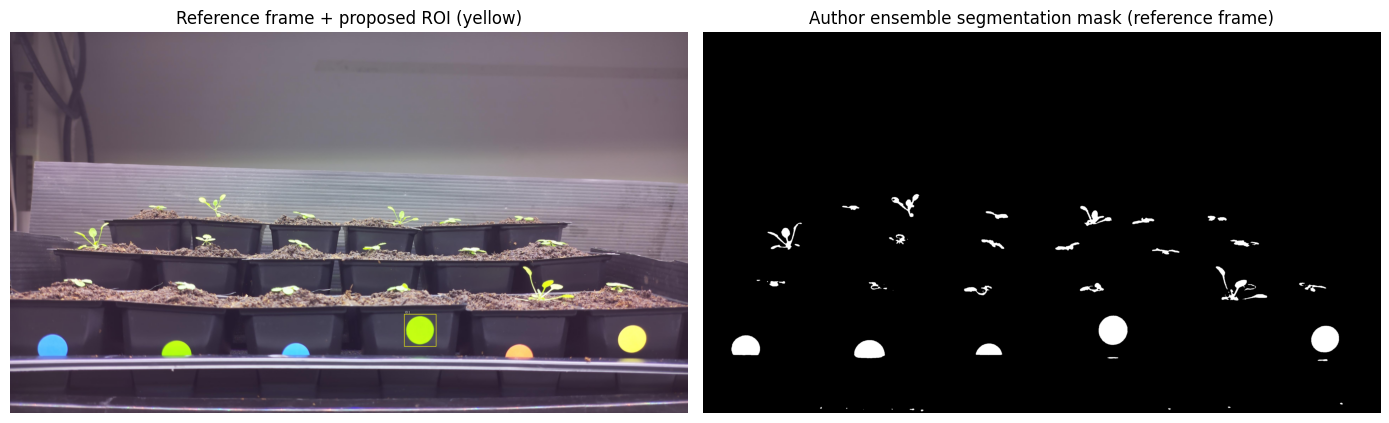

In [ ]:
overlay = ref.copy()
cv2.rectangle(overlay, (roi["x"], roi["y"]),
              (roi["x"] + roi["w"], roi["y"] + roi["h"]), (0, 255, 255), 2)
cv2.putText(overlay, f"ID {roi['id']}", (roi["x"] + 5, max(20, roi["y"] - 5)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 3, cv2.LINE_AA)
cv2.putText(overlay, f"ID {roi['id']}", (roi["x"] + 5, max(20, roi["y"] - 5)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
mask_rgb = cv2.cvtColor(ref_mask, cv2.COLOR_GRAY2RGB)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
ax[0].set_title("Reference frame + proposed ROI (yellow)"); ax[0].axis('off')
ax[1].imshow(mask_rgb)
ax[1].set_title("Author ensemble segmentation mask (reference frame)"); ax[1].axis('off')
plt.tight_layout(); plt.savefig("/content/roi_overlay.png", dpi=120); plt.show()

## Crop the seedling from every frame (author crop logic)

Apply the ROI to the subsampled frames exactly as `crop_apply_rois.py` does: clamp the padded
box to the image bounds and write one crop per frame (`pad_px=8` already included in the ROI).

**日本語:** `crop_apply_rois.py` と同じ方法（パッド込みのボックスを画像内にクランプ）で、
サブサンプルした全フレームから ROI 部分を切り出します。

In [ ]:
crops = []
for p in frame_paths:
    im = cv2.imread(str(p), cv2.IMREAD_COLOR)
    assert im is not None, f"cannot read {p}"
    x0 = max(0, roi["x"]); y0 = max(0, roi["y"])
    x1 = min(im.shape[1], roi["x"] + roi["w"]); y1 = min(im.shape[0], roi["y"] + roi["h"])
    crops.append(im[y0:y1, x0:x1])
print("crops:", len(crops), "| crop shape:", crops[0].shape)

crops: 66 | crop shape: (182, 180, 3)


## Segment every crop and measure (author measurement code)

Run the author's ensemble segmenter on each crop and compute the author's morphological
parameters per frame (`time_point` = frame index in the subsample; the camera's frame interval
is not published, so time is expressed in frames). One segmentation preview is shown.

**日本語:** 各切り出し画像に著者のセグメンテーションを適用し、著者の形態パラメータを
フレームごとに計算します（カメラのフレーム間隔が非公開のため、時間軸はフレーム index）。

frame 0 params: {'area_pixels': 20111, 'centroid_x': 89.16, 'centroid_y': 89.89, 'num_components': 1}


     time_point  area_pixels  centroid_x  centroid_y  perimeter  \
min         0.0      18948.0       88.01       88.60     516.32   
max        65.0      20214.0       90.93       91.08     537.53   

     num_components  
min             1.0  
max             1.0  


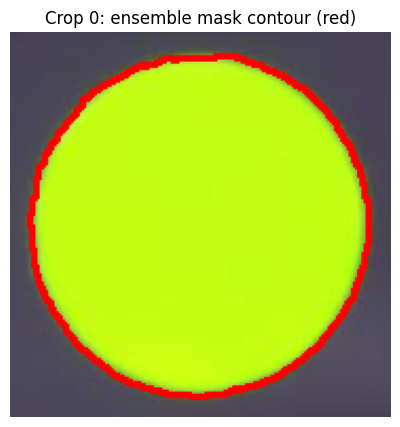

In [ ]:
rows = []
for tp, crop in enumerate(crops):
    mask = segmenter.segment_image(crop)
    params = calculate_morphological_parameters(mask, Path(frame_paths[tp]).name,
                                               None, 50, True)
    params["time_point"] = tp
    rows.append(params)
    if tp == 0:
        viz = crop.copy()
        cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(viz, cnts, -1, (0, 0, 255), 2)
        print("frame 0 params:", {k: params[k] for k in
              ("area_pixels", "centroid_x", "centroid_y", "num_components")})

import pandas as pd
df = pd.DataFrame(rows)
print(df[["time_point", "area_pixels", "centroid_x", "centroid_y", "perimeter",
          "num_components"]].describe().loc[["min", "max"]])
plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(viz, cv2.COLOR_BGR2RGB))
plt.title("Crop 0: ensemble mask contour (red)"); plt.axis('off'); plt.show()

## Y-displacement trajectory and area over time

Plot the author-defined centroid Y (up-positive, pixels) and plant area across the subsampled
frames. In the paper, such trajectories are detrended/normalised (BioDare2) and peak-analysed
(`P1_Peakfinder.m`) to quantify leaf movements — those stages are out of scope here, so this
shows the raw measured series only.

**日本語:** 著者定義の重心Y（上方向正、ピクセル）と植物面積の系列をプロットします。
論文ではこの後 BioDare2 によるデトレンド・正規化とピーク解析が行われますが、ここでは
生の計測系列のみを示します。

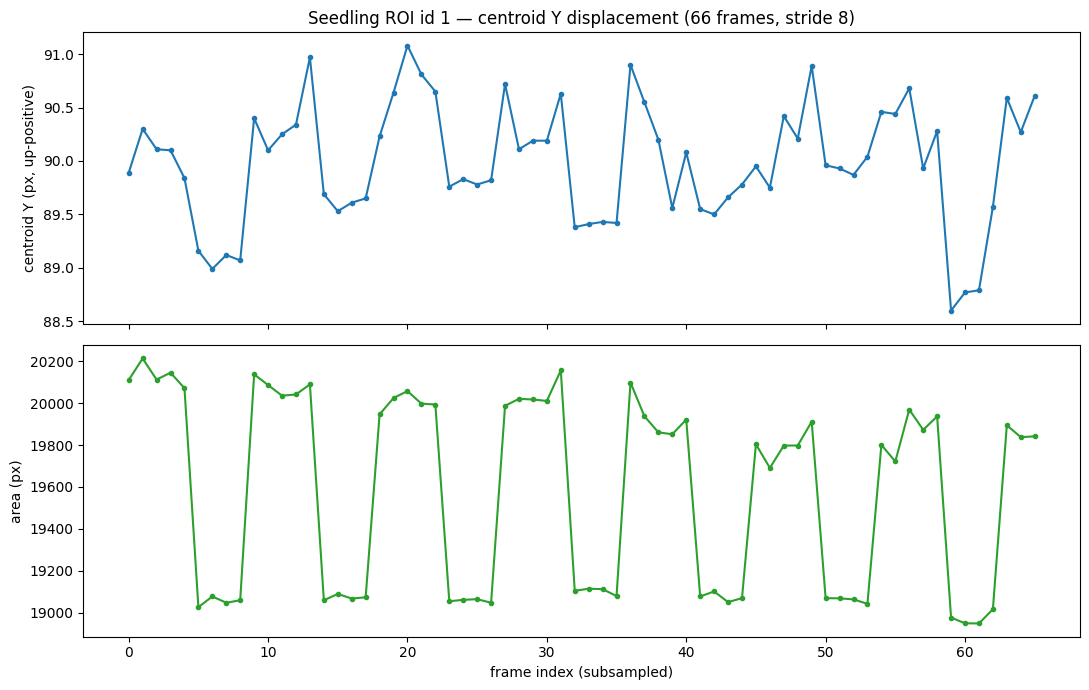

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(df["time_point"], df["centroid_y"], marker="o", ms=3)
ax[0].set_ylabel("centroid Y (px, up-positive)")
ax[0].set_title(f"Seedling ROI id {roi['id']} — centroid Y displacement ({len(df)} frames, stride {stride})")
ax[1].plot(df["time_point"], df["area_pixels"], marker="o", ms=3, color="tab:green")
ax[1].set_ylabel("area (px)"); ax[1].set_xlabel("frame index (subsampled)")
plt.tight_layout(); plt.savefig("/content/y_displacement.png", dpi=120); plt.show()

## Results table and CSV export

Show the measured table and export it to CSV in the Colab workspace.

**日本語:** 計測テーブルを表示し、CSV に保存します。

In [ ]:
df.to_csv("/content/seedling01_measurements.csv", index=False)
df[["time_point", "image_name", "area_pixels", "centroid_x", "centroid_y",
    "perimeter", "aspect_ratio", "circularity", "solidity", "num_components"]]

,time_point,image_name,area_pixels,centroid_x,centroid_y,perimeter,aspect_ratio,circularity,solidity,num_components
0,0,AvgNoIR-2025-09-05_10-10-34.jpg,20111,89.16,89.89,534.94,1.00,0.883,0.990,1
1,1,AvgNoIR-2025-09-05_12-50-33.jpg,20214,89.09,90.30,537.53,1.02,0.879,0.990,1
2,2,AvgNoIR-2025-09-05_15-30-33.jpg,20113,89.13,90.11,537.19,1.00,0.876,0.989,1
3,3,AvgNoIR-2025-09-05_18-10-34.jpg,20146,89.10,90.10,536.94,1.00,0.878,0.989,1
4,4,AvgNoIR-2025-09-05_20-50-35.jpg,20072,89.31,89.84,534.94,1.01,0.881,0.991,1
...,...,...,...,...,...,...,...,...,...,...
61,61,AvgNoIR-2025-09-12_04-50-34.jpg,18948,89.73,88.79,516.56,1.01,0.892,0.991,1
62,62,AvgNoIR-2025-09-12_07-30-36.jpg,19016,89.00,89.57,517.97,1.01,0.891,0.991,1
63,63,AvgNoIR-2025-09-12_10-10-35.jpg,19895,90.05,90.59,529.63,1.00,0.891,0.991,1
64,64,AvgNoIR-2025-09-12_12-50-38.jpg,19838,90.50,90.27,527.87,1.00,0.895,0.990,1


## Interpretation, provenance and limitations

**What was reproduced:** the paper's segmentation-and-measurement stage on Figure 3 dimG
time-lapse data — the author's exact ensemble segmentation (2-of-3 HSV/LAB/Otsu vote),
crop-per-ROI, and morphological parameters with the up-positive centroid Y that feeds the paper's
displacement analysis.

**Provenance:** author code pinned at `3cc9885` (MIT); data from Figshare record 32070474
(file 63917838, md5-verified above); paper DOI 10.1111/tpj.71119.

**Not reproduced / limitations:**
- BioDare2 detrending/normalisation and `P1_Peakfinder.m` period extraction (out of scope: external
  web service + MATLAB scripts embargoed under Apollo CAM.130058).
- No pixel-per-unit calibration is published (authors' ROI CSV is not public), so measurements are in pixels.
- ROI is AI-proposed instead of human-drawn (labeled above); frame subsample instead of every frame.
- Single example — this demonstrates the method on one sequence and does not verify the paper's
  dataset-level findings.

**日本語（要約）:** 本ノートブックは Figure 3 の dimG タイムラプス1系列に対する
セグメンテーション〜形態計測段階（著者コード逐語、重心Y上向き正）を再現します。
BioDare2 による周期解析と embargo 中の MATLAB スクリプトは範囲外、スケール較正は非公開のため
単位はピクセル、ROI は AI による自動提案（明記済み）、フレームは間引き処理です。
1例の実行であり、論文のデータセット全体の結論の検証ではありません。